# Statystyka zdarzeń

Zbiór do analizy: baza `2026-10-18 obiekt`, sesja 9, obecny wariant reguł sygnałów (`CURRENT_VARIANT`), tylko zdarzenia przyjęte. Plik rozpakowuje się z kopii w repo:

```shell
xz -dkc data/snapshots/prepared-obiekt-sesja-9.db.xz > data/prepared/obiekt-sesja-9.db
```

Dla każdego zdarzenia (`dms_analysis.event_stats`) różnica = wskazanie po − wskazanie przed (odsyp ujemna, zasyp dodatnia), średnia prędkość = różnica / czas trwania sygnału. Wskazania przed i po liczone dwiema metodami (`METHODS`), do porównania:

- **mediana 3 s** — mediana z 3 s przed początkiem i z 3 s po końcu,
- **najbliższa próbka** — wskazanie najbliższe w czasie początkowi i końcowi sygnału, bez wygładzania.

Kolizja = zdarzenie drugiej roli w odległości mniejszej niż `COLLISION_MARGIN`. Przedziały histogramów różnic to wielokrotności działki (20 kg).

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import pandas as pd
from IPython.display import display

from dms_analysis.event_stats import (
    METHODS,
    differences_by_method,
    event_differences,
    histogram,
    method_histograms,
)
from dms_analysis.prepared import load_session
from dms_analysis.signals import CURRENT_VARIANT
from dms_analysis.snapshot import ANALYSIS_SESSION, ANALYSIS_SOURCE

DB_PATH = Path("../data/prepared/obiekt-sesja-9.db")
FIGURE_WIDTH = 1200
DIFFERENCE_BIN_KG = 20
DURATION_BIN_S = 2
RATE_BIN_KG_S = 0.5

pd.set_option("display.max_rows", 500)

In [2]:
session = load_session(DB_PATH, ANALYSIS_SOURCE, ANALYSIS_SESSION, CURRENT_VARIANT)
table = event_differences(session)
events = table[table["method"] == next(iter(METHODS))]
rejected = session.events[session.events["rejected"]].groupby("role").size().rename("odrzucone")

for name, method in METHODS.items():
    print(f"{name}: {method.description()}")
events.groupby("role").agg(przyjęte=("start", "size"), kolizje=("collision", "sum")).join(rejected)

mediana 3 s: mediana z 3 s przed początkiem i po końcu sygnału
najbliższa próbka: próbka najbliższa początkowi i końcowi sygnału


,przyjęte,kolizje,odrzucone
role,,,
odsyp,221,0,42
zasyp,5,0,2


In [3]:
table.groupby(["role", "method"], sort=False)[["difference_kg", "rate_kg_s"]].describe().round(1)

difference_kg                                         \
                                count     mean      std    min    25%    50%   
role  method                                                                   
zasyp mediana 3 s                 5.0  10432.0  14342.2 -100.0  -40.0   20.0   
      najbliższa próbka           5.0  10440.0  14334.9 -100.0    0.0   20.0   
odsyp mediana 3 s               221.0   -270.3    131.1 -680.0 -340.0 -240.0   
      najbliższa próbka         221.0   -271.0    132.9 -680.0 -340.0 -260.0   

                                          rate_kg_s                        \
                             75%      max     count mean  std   min   25%   
role  method                                                                
zasyp mediana 3 s        25740.0  26540.0       5.0  4.4  7.7  -3.1  -1.8   
      najbliższa próbka  25740.0  26540.0       5.0  5.0  7.0  -1.8   0.0   
odsyp mediana 3 s         -200.0    200.0     221.0 -7.8  3.4 -17.4  -9.4   
      najbliższa próbka   -200.0    180.0     221.0 -7.9  3.7 -22.9 -10.0   

                                         
                         50%  75%   max  
role  method                             
zasyp mediana 3 s        2.2  9.5  15.0  
      najbliższa próbka  2.2  9.5  15.0  
odsyp mediana 3 s       -7.5 -5.7   4.1  
      najbliższa próbka -7.7 -5.7   2.9

## Odsypy

Prędkość odsypu policzona dodatkowo (przyda się przy wyliczaniu mas przy kolizjach). Czas trwania nie zależy od metody.

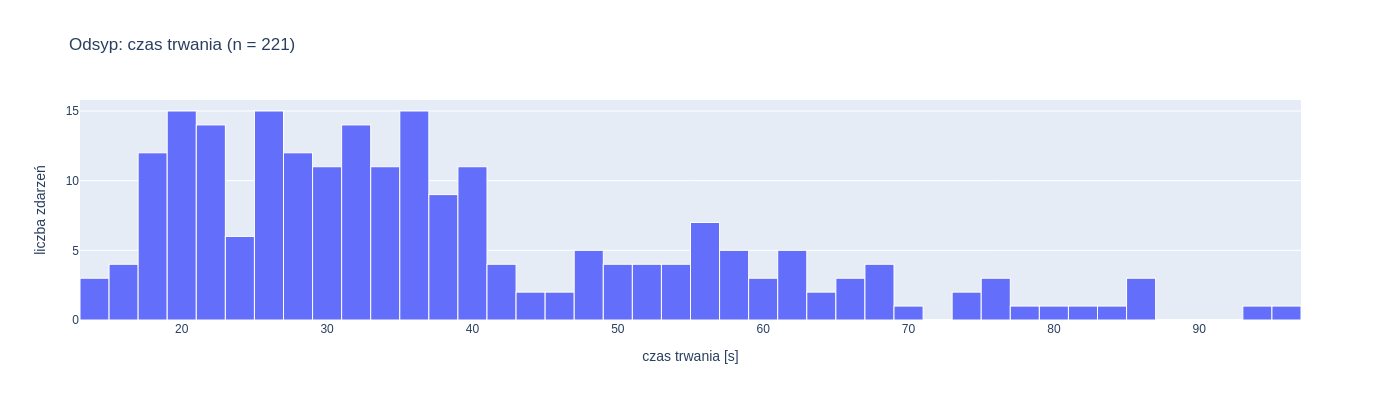

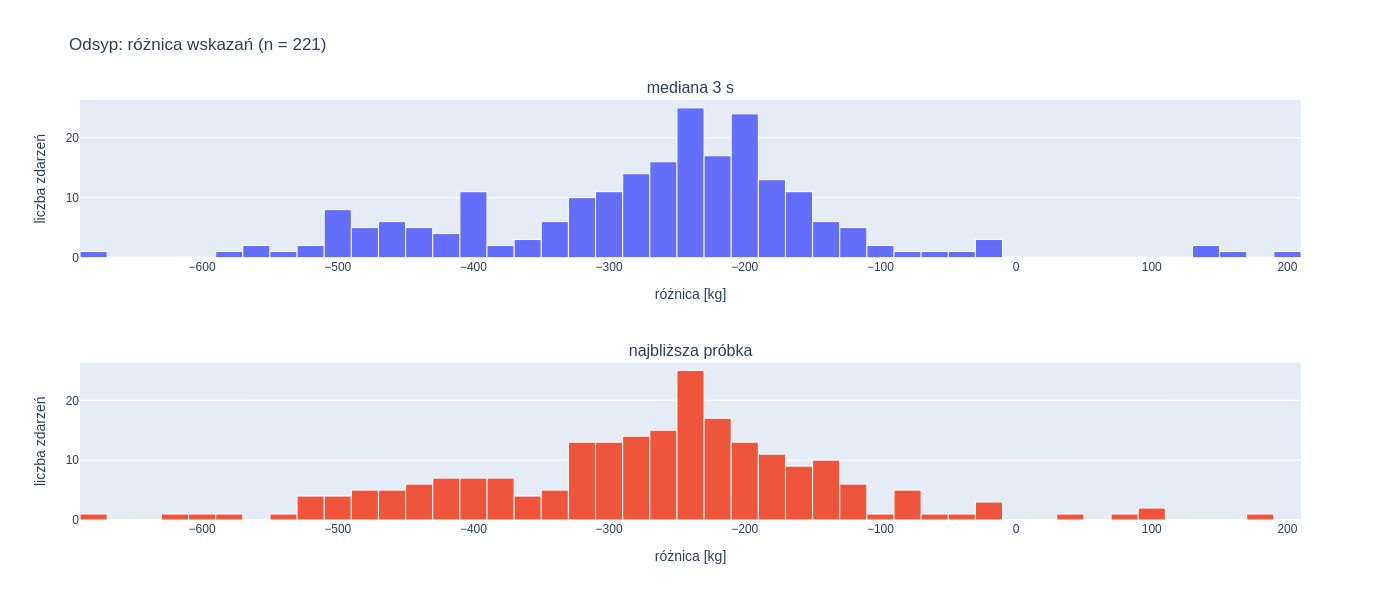

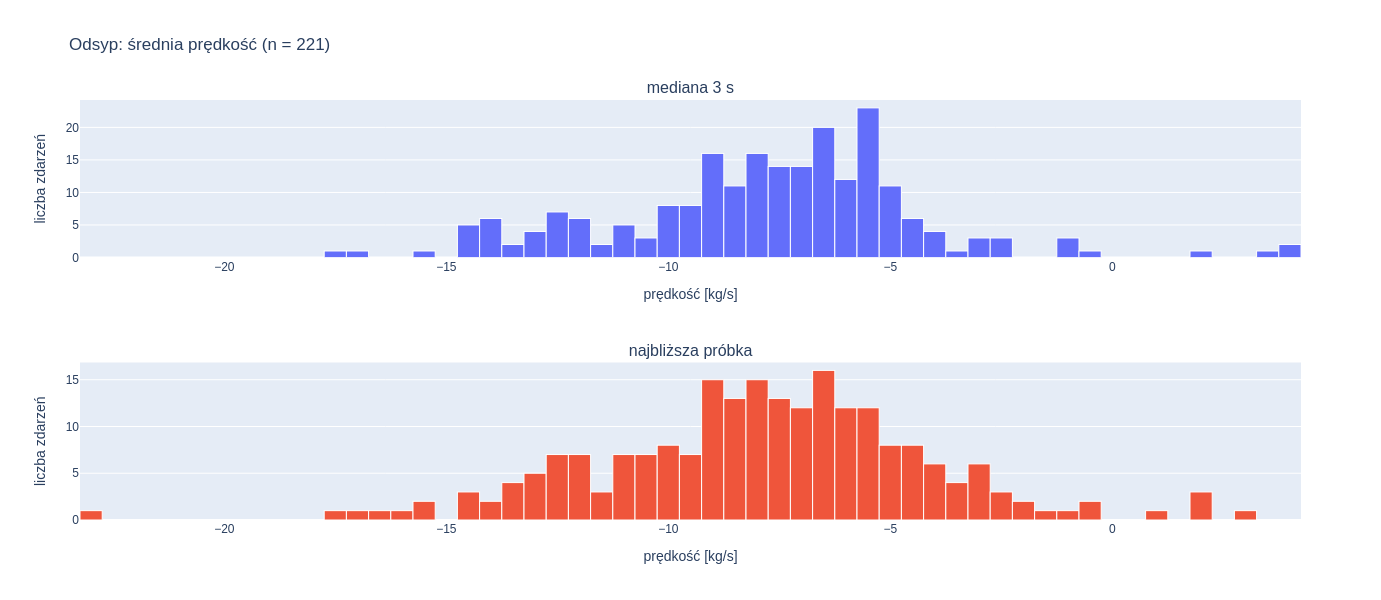

In [4]:
dispense = table[(table["role"] == "odsyp") & ~table["collision"]]

display(histogram(events.loc[events["role"] == "odsyp", "duration_s"], "Odsyp: czas trwania", "czas trwania [s]", DURATION_BIN_S, FIGURE_WIDTH))
display(method_histograms(dispense, "difference_kg", "Odsyp: różnica wskazań", "różnica [kg]", DIFFERENCE_BIN_KG, FIGURE_WIDTH))
display(method_histograms(dispense, "rate_kg_s", "Odsyp: średnia prędkość", "prędkość [kg/s]", RATE_BIN_KG_S, FIGURE_WIDTH))

Różnice metod dla każdego odsypu, posortowane po największej rozbieżności między metodami:

In [5]:
comparison = differences_by_method(dispense)
spread = comparison[list(METHODS)].max(axis=1) - comparison[list(METHODS)].min(axis=1)
comparison.assign(rozrzut_kg=spread).sort_values("rozrzut_kg", ascending=False)

method,role,start,mediana 3 s,najbliższa próbka,rozrzut_kg
13,odsyp,2026-09-26 11:23:05.562986851+02:00,-320.0,80.0,400.0
199,odsyp,2026-10-03 18:18:50.956979752+02:00,-20.0,-280.0,260.0
15,odsyp,2026-09-26 11:31:17.186964273+02:00,-460.0,-620.0,160.0
26,odsyp,2026-09-26 12:34:19.309546709+02:00,-200.0,-60.0,140.0
18,odsyp,2026-09-26 12:04:52.718340158+02:00,-400.0,-260.0,140.0
69,odsyp,2026-09-30 11:08:56.015146971+02:00,-280.0,-140.0,140.0
11,odsyp,2026-09-24 20:01:15.413933516+02:00,-440.0,-300.0,140.0
25,odsyp,2026-09-26 12:32:25.725691080+02:00,-240.0,-120.0,120.0
19,odsyp,2026-09-26 12:10:39.229726791+02:00,-400.0,-280.0,120.0
52,odsyp,2026-09-27 11:54:35.001663446+02:00,-240.0,-360.0,120.0


Odsypy z różnicą nieujemną w którejkolwiek metodzie (wbrew oczekiwanemu spadkowi):

In [6]:
comparison[(comparison[list(METHODS)] >= 0).any(axis=1)]

method,role,start,mediana 3 s,najbliższa próbka
1,odsyp,2026-09-24 15:57:44.501525879+02:00,140.0,40.0
13,odsyp,2026-09-26 11:23:05.562986851+02:00,-320.0,80.0
76,odsyp,2026-09-30 12:15:39.243706465+02:00,140.0,100.0
115,odsyp,2026-10-01 15:54:59.009107351+02:00,160.0,100.0
119,odsyp,2026-10-01 16:16:19.466265202+02:00,200.0,180.0


## Zasypy

Zasypów jest kilka, więc zamiast histogramu tabela; histogram ma sens dopiero na większej liczbie danych.

In [7]:
table[table["role"] == "zasyp"].sort_values("start", kind="stable")

,role,start,end,duration_s,collision,method,before_kg,after_kg,difference_kg,rate_kg_s
0,zasyp,2026-09-24 15:34:57.953909159+02:00,2026-09-24 15:35:54.995967627+02:00,57.042058,False,mediana 3 s,44800.0,44700.0,-100.0,-1.753092
226,zasyp,2026-09-24 15:34:57.953909159+02:00,2026-09-24 15:35:54.995967627+02:00,57.042058,False,najbliższa próbka,44800.0,44700.0,-100.0,-1.753092
1,zasyp,2026-09-25 18:05:12.586299419+02:00,2026-09-25 18:05:25.344811678+02:00,12.758512,False,mediana 3 s,45300.0,45260.0,-40.0,-3.135162
227,zasyp,2026-09-25 18:05:12.586299419+02:00,2026-09-25 18:05:25.344811678+02:00,12.758512,False,najbliższa próbka,45300.0,45300.0,0.0,0.000000
2,zasyp,2026-09-25 18:05:45.360014439+02:00,2026-09-25 18:35:19.738622189+02:00,1774.378608,False,mediana 3 s,45280.0,71820.0,26540.0,14.957349
228,zasyp,2026-09-25 18:05:45.360014439+02:00,2026-09-25 18:35:19.738622189+02:00,1774.378608,False,najbliższa próbka,45280.0,71820.0,26540.0,14.957349
3,zasyp,2026-09-25 18:35:36.501876593+02:00,2026-09-25 18:35:45.758313894+02:00,9.256437,False,mediana 3 s,71800.0,71820.0,20.0,2.160659
229,zasyp,2026-09-25 18:35:36.501876593+02:00,2026-09-25 18:35:45.758313894+02:00,9.256437,False,najbliższa próbka,71800.0,71820.0,20.0,2.160659
4,zasyp,2026-10-02 15:08:20.512807131+02:00,2026-10-02 15:53:17.770470858+02:00,2697.257664,False,mediana 3 s,23360.0,49100.0,25740.0,9.543026
230,zasyp,2026-10-02 15:08:20.512807131+02:00,2026-10-02 15:53:17.770470858+02:00,2697.257664,False,najbliższa próbka,23340.0,49080.0,25740.0,9.543026
